<a href="https://colab.research.google.com/github/tachom-a11/111111/blob/main/ipynb/ex_MNIST_LogisticRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MNIST画像のロジスティック回帰（logistic regression on MNIST datasets）

MNIST画像の識別問題において，ロジスティック回帰で学習した単純パーセプトロンの重みを可視化します．

----

氏名：TIAN XINYE

学生番号：38926501

----
## 基本課題（必須）

    1. 「★ロジスティック回帰を実行します．」で，損失の係数`C`を小さい値に設定し，L2正則化の効果を強くすると，
       訓練データ（training data）と検証データ（validation data）の正答率はどう変わりますか．
       また，パーセプトロンの重みはどうなりますか．

Cを小さくすると，訓練データと検証データの正答率はどちらも下がりました．これは，L2正則化付きの目的関数が

$$\min_{\mathbf{w},b}\ \frac{1}{2}\|\mathbf{w}\|^2 + C\sum_{i=1}^{n}\log\left(1+e^{-y_i(\mathbf{w}^\top\mathbf{x}_i+b)}\right)$$

だからです．Cが小さくなると，重みの範囲がとても小さく制限されます．その範囲の中での最適な値は，データをうまく分類できるほど良い値ではないので，未学習になります．パーセプトロンの重みを可視化すると，Cが小さくなるにつれて，数字の輪郭がだんだんはっきりしてきました．これは，Cが小さくなるとペナルティが大きくなり，正則化によってばらばらな重みができるだけ引き戻されて，0付近に落ち着くからです．



    2. 「★学習した重みを可視化し，識別関数を計算します．」を実行すると，
       (a)識別に役立つ特徴が学習によって見つけられていること，(b)識別的特徴に基づき識別関数が計算されていること  
       を観察できます．表示される図や数値をどのように見ると(a)と(b)を確認できますか．
      
(a)は1枚目の図で確認できます．1枚目の図では，青は負の重み，赤は正の重みを表しています．赤い部分は，そこに画素があるほどその数字である可能性が高くなる特徴で，青い部分は，その数字ではないことを示す特徴です．

(b)は3枚目の図で確認できます．3枚目の図は，1枚目の重みと2枚目の画像の画素値を画素ごとに掛け合わせたもので，2枚目の画像で白くなっている，つまり識別したい対象がある部分の色だけが表示されています．3枚目の図で対象の部分に赤が多いほど，その画像がそのクラスであるとより確信していることを表しています．そして，これらを足し合わせることで，次の式のように識別関数の値 $g$ が計算されます．

$$g = \sum_{i} w_i x_i + b $$

ここで，$w_i$ は各画素の重み，$x_i$ は各画素の値，$b$ は切片です．$g \geq 0$ のとき，その画像はそのクラスであると判定されます．反対に青が多い場合は $g$ が負になり，その対象ではないと判定されます．





    3. 手書き数字画像以外のデータ集合（例えばFashion-MNIST）で2つのクラスを選択し，2クラス識別器を作成してください．
       パーセプトロンの重みから，その2つのクラスにはどのような特徴の違いが見つかりましたか．
       また，「★ロジスティック回帰を実行します．」において，どのような設定でLogisticRegression()を使用すると，
       選択した2クラスの識別的特徴が考察しやすいですか．


Fashion-MNISTのTシャツとズボンの2クラスを選びました．重みwを可視化した図では，赤がズボンの特徴，青がTシャツの特徴を表しています．中央にはズボンの形がはっきりと赤く表れています．ズボンには袖がないので，両側の袖の部分は青くなっていて，Tシャツの特徴を表しています．また，中央にも1本の青い線があります．これは，ズボンでは2本の脚の間が空白なので，その部分に何かあるのはTシャツだけだからです．Tシャツはズボンより裾が少し広いので，裾の外側の部分も青くなっています．

LogisticRegression()では，正則化を使って大きすぎる重みにペナルティをかけ，重みをある範囲の中に収めるようにすると，重みの図がよりなめらかになり，袖や脚の形もよりはっきり見えるようになります．ただし，Cを小さくしすぎると未学習になるので，小さくしすぎないようにする必要があります．

ここでは，L1正則化，L2正則化，ElasticNet正則化をそれぞれ使いました．最初に正則化を加えない場合，重みは非常にばらばらで，ノイズのように規則性がありませんでした．L1正則化を使うと，正則化を加えない場合に比べるとノイズは少なくなりましたが，まだノイズが比較的多く，服やズボンの形はあまりよくわかりませんでした．一方，ElasticNet正則化を使うと，重みがとても疎になり，赤い点と青い点が重要な位置にだけ残るので，服とズボンのおおよその形がわかりました．L2正則化を使うと，重みの図がとてもはっきりして，ズボンの形や服の形が重みの図からほぼそのままわかりました．



    4.その他，気づいたこと，調べたことがあれば書いてください．

ElasticNetは，L1正則化とL2正則化を組み合わせた正則化です．L1は重みをちょうど0にして特徴を選択できますが，相関の高い特徴の中から1つだけを選んで残りを0にしてしまうことがあり，特徴の数がサンプルの数より多い場合にはサンプルの数までしか特徴を選べないという限界があります．一方，L2は重みを0付近までしか小さくできませんが，相関の高い特徴に重みを均等に分けて両方を残すことができ，目的関数を強凸にして最適解を1つに決めることができます．ElasticNetはこの両方の長所を持っていて，重みを0にして特徴を選択しながら，相関の高い特徴をいっしょに残すことができます．

今回の実験では，ElasticNetの重みは，残っている部分は連なっていましたが，連なっていない部分のすき間はとても大きかったです．重みが連なって残っているのは，L2によって相関の高い隣どうしの画素がいっしょに残されるからだと考えられます．しかし，L2のこの効果は，L1によって0にされずに残った画素どうしの間でしか働きません．Tシャツとズボンの識別にあまり役立たない画素はL1によってまとめて0にされます．



----
発展課題（任意）がこのノートブックの後半にあります．

### データ集合を取得します．

In [5]:
from torchvision import datasets

# [MNIST](http://yann.lecun.com/exdb/mnist/)
#tvds = datasets.MNIST('./data', download=True, train=True)

# [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist)
tvds = datasets.FashionMNIST('./data', download=True, train=True)

# [Kuzushiji-MNIST](https://github.com/rois-codh/kmnist)
#tvds = datasets.KMNIST('./data', download=True, train=True)

Ximages_all, y_all = tvds.data.numpy(), tvds.targets.numpy()

# [EMNIST](https://pytorch.org/vision/stable/generated/torchvision.datasets.EMNIST.html)
#tvds = datasets.EMNIST('./data', download=True, train=True, split='letters')
#Ximages_all, y_all = tvds.data.transpose_(-1,-2).numpy(), tvds.targets.numpy() - 1

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 266kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.00MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.1MB/s]


In [40]:
#@title ☆画像数とサイズを確認します（画像を加工したい場合はこのセルを編集して利用してください）．
import numpy as np
from skimage.filters import gaussian
from skimage.exposure import equalize_hist as eh
from skimage.transform import resize

Ximages = Ximages_all.copy()
y = y_all.copy()

'''
* blurring (https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.gaussian)
* histogram equalization (https://scikit-image.org/docs/stable/auto_examples/color_exposure/plot_equalize.html)
* resize images (https://scikit-image.org/docs/stable/auto_examples/transform/plot_rescale.html)
'''
#Ximages = gaussian(np.float32(Ximages_all.transpose((1,2,0))), sigma=1.0, multichannel=True).transpose(2,0,1)
#Ximages = eh(Ximages_all.transpose((1,2,0))).transpose(2,0,1) * 255
#height, width = 8, 8; Ximages = resize(np.float32(Ximages_all.transpose((1,2,0))), (height, width)).transpose(2,0,1)

''' simulate noisy images '''
#Ximages = Ximages + np.random.rand(*Ximages.shape) * 200; Ximages = np.clip(Ximages,a_min=0,a_max=255)

Ximages = np.uint8(Ximages)
print("(#images, height, width)", Ximages.shape)
print(Ximages.dtype, ", max. pixel value = ", Ximages.max())

(#images, height, width) (4708, 28, 28)
uint8 , max. pixel value =  255


MNIST class labels

| [MNIST](http://yann.lecun.com/exdb/mnist/) | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
| - | :-: | :-: | :-: | :-: | :-: | :-: | :-: | :-: | :-: | :-: |
| [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) | T-shirt/top | Trouser | Pullover | Dress | Coat | Sandal |  Shirt | Sneaker | Bag | Ankle boot |
| [Kuzushiji-MNIST](https://github.com/rois-codh/kmnist) | お | き | す | つ | な | は |  ま | や | れ | を |

12000 images in total


<Figure size 640x480 with 0 Axes>

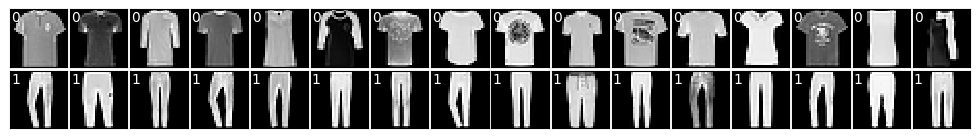

In [38]:
#@title 画像を表示する関数 implot を定義し，画像を例示します．
%matplotlib inline
!wget -q -N https://gist.githubusercontent.com/tsakai-g/c54a8fa059f9c655290586ec1cc2ec7b/raw/implot.py
%run implot.py

print("%d images in total" % len(y))
p = np.random.permutation(len(y))
implot(Ximages[p], y[p], num=16, vmin=0, vmax=255)

### 2クラスの識別問題にしたい場合（さもなくば実行しないこと）
- このセルの `pos` と `neg` で2クラスを指定します．
- 全クラスを使う場合に戻したいときは「☆画像数とサイズを確認します」のセルから実行し直してください．

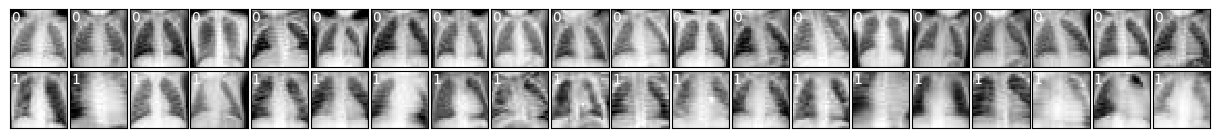

In [41]:
pos = 1 # choose from 0 to 9
neg = 0 # choose from 0 to 9

Ximages = Ximages[np.logical_or(y == pos, y == neg)]
y = y[np.logical_or(y == pos, y == neg)]
yp, yn = y == pos, y== neg
y[yp] = 1
y[yn] = 0

p = np.random.permutation(len(y))
implot(Ximages[p], y[p], num=20)

### 訓練データと検証データに分けます．
- `n_train` と `n_val` で訓練データと検証データの数をそれぞれ指定できます．

In [42]:
n_train = 3000
n_val = 1000

from sklearn.model_selection import train_test_split
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

# split the data into training and validation sets
Ximages_train, Ximages_val, y_train, y_val = train_test_split(Ximages, y,
                                                              train_size=n_train, test_size=n_val)

# reshape to 28*28=784-dimensional feature vectors
X_train = np.reshape(Ximages_train, (Ximages_train.shape[0], -1)) / 255   # (n_train, 784)
X_val = np.reshape(Ximages_val, (Ximages_val.shape[0], -1)) / 255         # (n_val, 784)
print("X_train.shape = ", X_train.shape)
print("X_val.shape = ", X_val.shape)

X_train.shape =  (3000, 784)
X_val.shape =  (1000, 784)


### ★ロジスティック回帰を実行します．
- [sklearn.linear_model.LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)を使用します．引数の仕様とデフォルトの値を確認してください．
- 実装されているロジスティック損失は訓練データ数で除された平均ではありません．[損失の係数`C`](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)で設定できます．

In [43]:
from sklearn.linear_model import LogisticRegression

# 反復数以外はデフォルトの値で実行します．
#model =  LogisticRegression(max_iter=1000)

# 損失の係数`C`を小さい値に設定し，L2正則化の効果を強くします．
model =  LogisticRegression(C=10/n_train, max_iter=1000, penalty='l2')

# [Elastic net regularization](https://en.wikipedia.org/wiki/Elastic_net_regularization) i.e., L1+L2 regularization
#model =  LogisticRegression(C=10000/n_train, penalty='elasticnet', l1_ratio=0.5, solver='saga')

# sparse regularization
#model =  LogisticRegression(penalty='l1', solver='saga')

model.fit(X_train, y_train)

LogisticRegression(C=0.0033333333333333335, max_iter=1000)

Accuracy on training data:  0.903


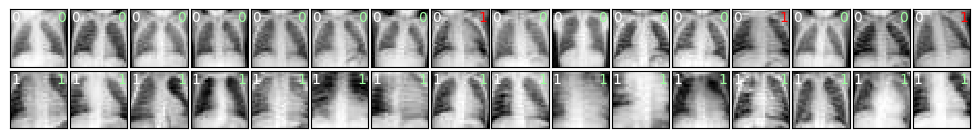


Accuracy on validation data:  0.905


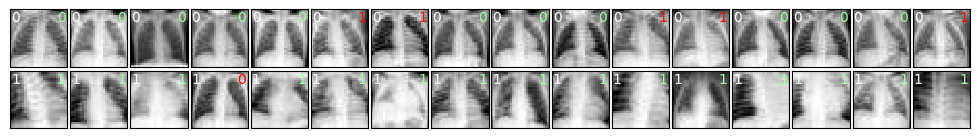

In [44]:
#@title 識別の結果を例示します（上：訓練データ，下：検証データ）．
%matplotlib inline
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_train)
print("Accuracy on training data: ", accuracy_score(y_train, y_pred))
p = np.random.permutation(n_train)
implot(Ximages_train[p], y_train[p], y_pred[p], num=16)
plt.show()

y_pred = model.predict(X_val)
print("\nAccuracy on validation data: ", accuracy_score(y_val, y_pred))
p = np.random.permutation(n_val)
implot(Ximages_val[p], y_val[p], y_pred[p], num=16)

MNIST class labels

| [MNIST](http://yann.lecun.com/exdb/mnist/) | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
| - | :-: | :-: | :-: | :-: | :-: | :-: | :-: | :-: | :-: | :-: |
| [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) | T-shirt/top | Trouser | Pullover | Dress | Coat | Sandal |  Shirt | Sneaker | Bag | Ankle boot |
| [Kuzushiji-MNIST](https://github.com/rois-codh/kmnist) | お | き | す | つ | な | は |  ま | や | れ | を |

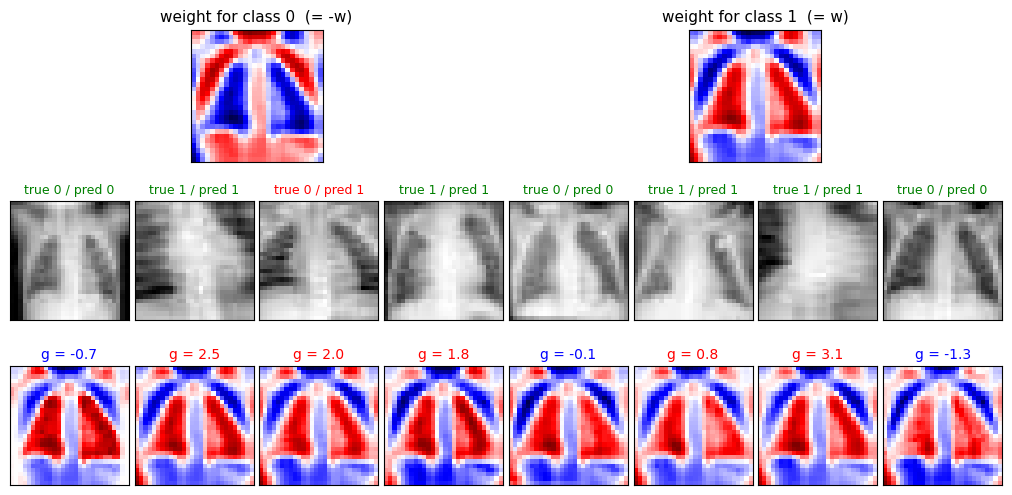

In [45]:
#@title ★学習した重みを可視化し，識別関数を計算します（複数画像）

from matplotlib.colors import TwoSlopeNorm as tsn
import matplotlib.gridspec as gridspec

N = 8                    # 表示する画像の枚数（偶数にすると各クラス半分ずつ）
# np.random.seed(0)      # 毎回同じ画像を見たいときはコメントを外す

w_all = np.c_[model.intercept_, model.coef_]
wk = w_all[0, 1:]        # 各画素の重み（classes[1] 側が正）
b = w_all[0, 0]          # 切片
H, W = Ximages.shape[1], Ximages.shape[2]
cmap = plt.cm.seismic
classes = model.classes_

# y_val がクラス番号でもラベルそのものでも動くように揃える
y_true = y_val if np.isin(y_val, classes).all() else classes[y_val]
y_pred = model.predict(X_val)

# 各クラスから N/2 枚ずつランダムに選んで混ぜる
picks = []
for cls in classes:
    idx = np.where(y_true == cls)[0]
    picks += list(np.random.choice(idx, N // len(classes), replace=False))
np.random.shuffle(picks)

fig = plt.figure(figsize=(1.6 * N, 6))
gs = gridspec.GridSpec(3, N, figure=fig, hspace=0.25, wspace=0.05)

def show_weight(ax, wmap, title):
    norm = tsn(vmin=min(wmap.min(), -1e-6), vcenter=0, vmax=max(wmap.max(), 1e-6))
    ax.imshow(wmap.reshape(H, W), cmap=cmap, norm=norm)
    ax.set_title(title, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

# 1行目：クラス0の重み（-w）とクラス1の重み（w）
half = N // 2
show_weight(fig.add_subplot(gs[0, :half]), -wk, f'weight for class {classes[0]}  (= -w)')
show_weight(fig.add_subplot(gs[0, half:]),  wk, f'weight for class {classes[1]}  (= w)')

# 2行目：画像，3行目：w×x と g
for i, j in enumerate(picks):
    x = X_val[j, :].ravel()

    ax = fig.add_subplot(gs[1, i])
    ax.imshow(Ximages_val[j].squeeze(), cmap=plt.cm.gray)
    ok = (y_pred[j] == y_true[j])
    ax.set_title(f'true {y_true[j]} / pred {y_pred[j]}',
                 fontsize=9, color='green' if ok else 'red')
    ax.set_xticks([]); ax.set_yticks([])

    wx = x * wk
    g = wx.sum() + b
    ax = fig.add_subplot(gs[2, i])
    norm = tsn(vmin=min(wx.min(), -1e-6), vcenter=0, vmax=max(wx.max(), 1e-6))
    ax.imshow(wx.reshape(H, W), cmap=cmap, norm=norm)
    ax.set_title(f'g = {g:.1f}', fontsize=10, color='r' if g >= 0 else 'b')
    ax.set_xticks([]); ax.set_yticks([])

plt.show()

可視化の説明：
- <b>上段</b>：パーセプトロンの入力の画素値に対応する重みを図示しています．
    - 赤が正，青は負 の重みを表します．
    - 2クラスの場合は，正と負がそれぞれ`pos`と`neg`に寄与する重みです．
- <b>中段</b>：入力画像です．画素値は非負で，黒はゼロです．
- <b>下段</b>：パーセプトロンの重み（上段）と入力画像（中段）の画素値の積を図示しています．
- 各クラスのパーセプトロンが計算した識別関数 <i>g</i> を各列の下に表示しています．

In [9]:
#@title 混同行列（行：正解，列：予測）
from sklearn import metrics
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

cm = metrics.confusion_matrix(y_val, y_pred)
print(cm)

print(cm.sum(axis=0))

[[461   1]
 [  0 538]]
[461 539]


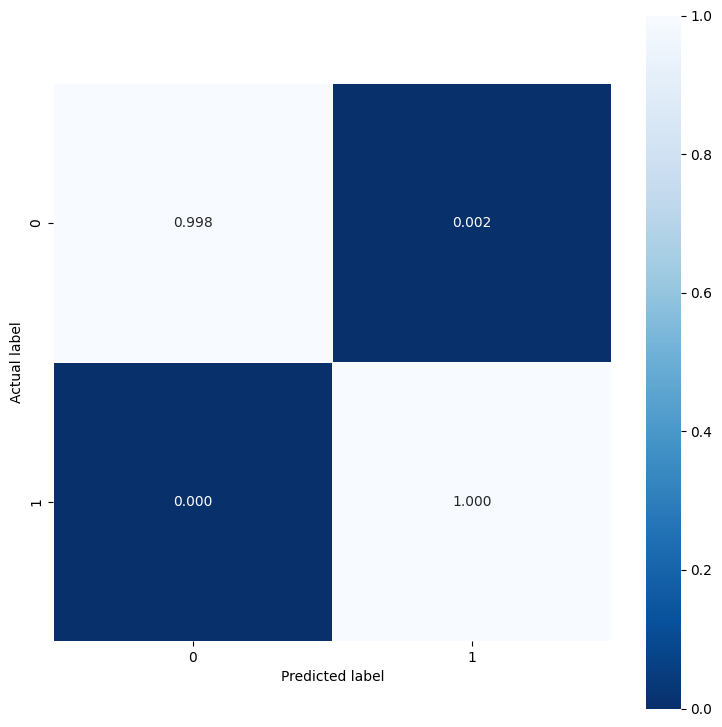

In [10]:
#@title おまけ
import seaborn as sns

# Make predictions on test data
cm = metrics.confusion_matrix(y_val, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(9,9))
sns.heatmap(cm_normalized, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');

--------
## 発展課題（任意）

[MedMNIST](https://github.com/MedMNIST/MedMNIST)を使ってましょう．
手書き数字画像のように手軽に使える実験用の医用画像です．  
下の2つのセルを実行後は，このJupyter Notebook前半の  
「☆画像数とサイズを確認します（画像を加工したい場合はこのセルを編集して利用してください）．」  
以降を実行できます．

    1. PneumoniaMNISTは胸部X線CT画像です．'0': 正常, '1': 異常（肺炎）の2クラス識別問題です．
       学習したパーセプトロンは，主に画像のどこの画素値をどのように重みづけしますか．

重みwの図を見ると，左右の肺の部分に赤が付けられていて，肋骨や胸郭など肺の外側の部分には青が付けられていました．X線画像では，正常な肺は空気が多くX線を通しやすいので黒く写ります．一方，肺炎になると肺胞に液体などがたまり，肺の中に白くぼやけた影が写ります．そのため，肺の部分の画素値が大きいほど肺炎である可能性が高くなり，肺の部分に正の重みが付けられたと考えられます．また，肺の外側に負の重みがあることで，識別関数は肺の部分と周りの部分の明るさの差を見ることになり，画像全体が明るい場合でも，肺だけが周りより白い場合に肺炎と判定できると考えられます．



    2. MedMNISTにはどのような医用画像の識別問題がありますか．

（ここに回答を書いてください）[参考文献](https://arxiv.org/abs/2110.14795)

MedMNISTには，12種類の2次元データセットと6種類の3次元データセットがあり，画像の大きさは2次元では28×28にそろえられています．2次元データセットには，大腸の病理組織画像を9クラスに分類するPathMNIST，胸部X線画像から14種類の疾患を多ラベル分類するChestMNIST，皮膚鏡画像を7クラスに分類するDermaMNIST，網膜のOCT画像を4クラスに分類するOCTMNIST，胸部X線画像を正常と肺炎の2クラスに分類するPneumoniaMNIST，眼底画像から糖尿病網膜症の程度を5段階で判定するRetinaMNIST，乳房の超音波画像を2クラスに分類するBreastMNIST，血液細胞の顕微鏡画像を8クラスに分類するBloodMNIST，腎臓の細胞の顕微鏡画像を8クラスに分類するTissueMNIST，腹部CT画像から11種類の臓器を分類するOrganAMNIST，OrganCMNIST，OrganSMNISTがあります.



In [36]:
#@title [MedMNIST](https://github.com/MedMNIST/MedMNIST)を取得します．
!pip install -q medmnist
import medmnist
print(f"MedMNIST v{medmnist.__version__} @ {medmnist.HOMEPAGE}")

MedMNIST v3.0.2 @ https://github.com/MedMNIST/MedMNIST/


In [39]:
# 'pneumoniamnist', 'chestmnist', 'octmnist', 'breastmnist', 'tissuemnist', 'organamnist', 'organcmnist', 'organsmnist'
data_flag = 'pneumoniamnist'
DataClass = getattr(medmnist, medmnist.INFO[data_flag]['python_class'])

tvds = DataClass(split='train', download=True)
#tvds = DataClass(split='test', download=True)

print(tvds)
Ximages_all, y_all = tvds.imgs, tvds.labels.ravel()

Dataset PneumoniaMNIST of size 28 (pneumoniamnist)
    Number of datapoints: 4708
    Root location: /root/.medmnist
    Split: train
    Task: binary-class
    Number of channels: 1
    Meaning of labels: {'0': 'normal', '1': 'pneumonia'}
    Number of samples: {'train': 4708, 'val': 524, 'test': 624}
    Description: The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.
    License: CC BY 4.0


お疲れさまでした．